Classifying movie reviews into positive reviews and negative reviews based on the text content using recurrent neural networks such as LSTM. Perform text preprocessing and evaluate classification performance. Using IMDB Movie Reviews Dataset from Link:
https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

In [2]:
import pandas as pd

df = pd.read_csv("IMDB Dataset.csv")

print(df.head())
print(df.shape)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)


Dataset Shape:
(50000, 2)

First 5 Records:
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

Missing Values:
review       0
sentiment    0
dtype: int64

Dataset after removing missing values:
(50000, 2)

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


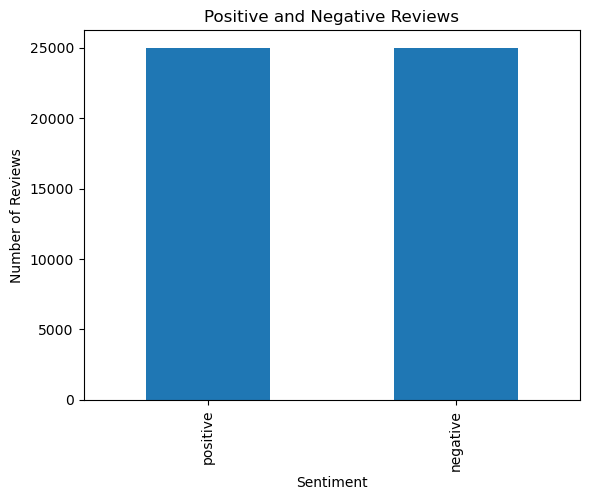


Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 200, 128)            │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,411,713 (5.39 MB)

 Trainable params: 1,411,713 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 48s 93ms/step - accuracy: 0.5139 - loss: 0.6967 - val_accuracy: 0.5111 - val_loss: 0.6915
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.5665 - loss: 0.6676 - val_accuracy: 0.5213 - val_loss: 0.6878
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.5516 - loss: 0.6823 - val_accuracy: 0.5211 - val_loss: 0.6891
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.5896 - loss: 0.6636 - val_accuracy: 0.6071 - val_loss: 0.6741
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.7208 - loss: 0.5609 - val_accuracy: 0.8115 - val_loss: 0.4501
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.8529 - loss: 0.3560 - val_accuracy: 0.8324 - val_loss: 0.3784
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 91ms/step - accuracy: 0.8907 - loss: 0.2797 - val_accuracy: 0.8511 - val_loss: 0.3524
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 91ms/step - accuracy: 0.9178 - loss: 0.2243 - 

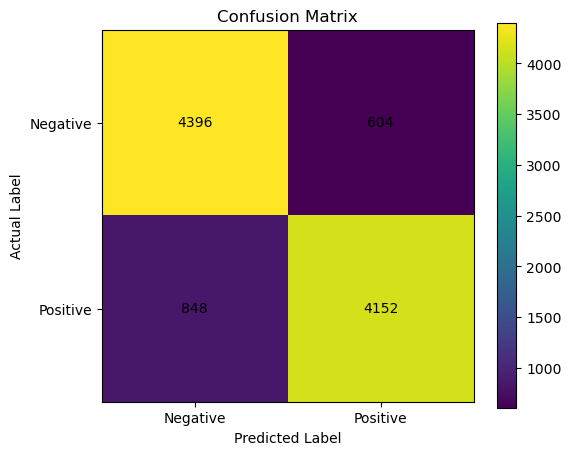

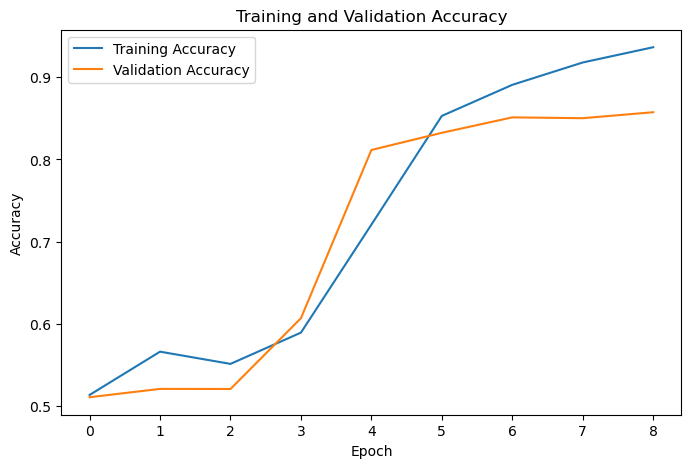

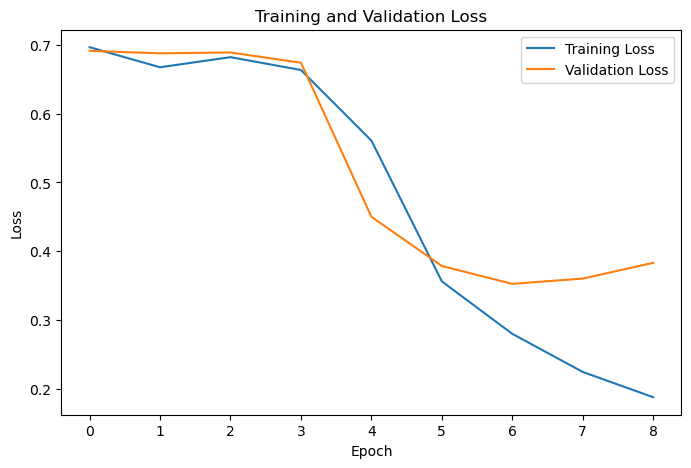


Review: This movie was absolutely amazing. I loved every minute of it.
Prediction: Positive
Probability: 0.9562

Review: The movie was boring and disappointing. I did not enjoy it.
Prediction: Negative
Probability: 0.1053


In [3]:
# ============================================================
# IMDB MOVIE REVIEW SENTIMENT CLASSIFICATION USING LSTM
# ============================================================

# 1. Import required libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 2. Load Dataset
# ============================================================

# If the CSV is in the same folder as your Python program


print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Records:")
print(df.head())


# ============================================================
# 3. Check Missing Values
# ============================================================

print("\nMissing Values:")
print(df.isnull().sum())


# Remove missing records if any
df = df.dropna()

print("\nDataset after removing missing values:")
print(df.shape)


# ============================================================
# 4. Check Class Distribution
# ============================================================

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

# Plot class distribution
df["sentiment"].value_counts().plot(kind="bar")
plt.title("Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


# ============================================================
# 5. Text Preprocessing
# ============================================================

def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags such as <br />
    text = re.sub(r"<br\s*/?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Keep only alphabets and spaces
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
df["clean_review"] = df["review"].apply(clean_text)

print("\nOriginal Review:")
print(df["review"].iloc[0])

print("\nCleaned Review:")
print(df["clean_review"].iloc[0])


# ============================================================
# 6. Convert Sentiment into Numerical Values
# ============================================================

# positive = 1
# negative = 0

df["label"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

print("\nEncoded Labels:")
print(df[["sentiment", "label"]].head())


# ============================================================
# 7. Separate Input and Output
# ============================================================

X = df["clean_review"]
y = df["label"]


# ============================================================
# 8. Split Dataset into Training and Testing
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ============================================================
# 9. Tokenization
# ============================================================

# Maximum number of words to keep
vocab_size = 10000

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Learn vocabulary from training reviews
tokenizer.fit_on_texts(X_train)


# Convert text into sequences of integers
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)


print("\nExample Tokenized Review:")
print(X_train_seq[0][:20])


# ============================================================
# 10. Padding
# ============================================================

# Maximum review length
max_length = 200

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("\nTraining Data Shape:", X_train_pad.shape)
print("Testing Data Shape:", X_test_pad.shape)


# ============================================================
# 11. Build LSTM Model
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

model = Sequential([
    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=128
    ),

    LSTM(128),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# ============================================================
# 13. Early Stopping
# ============================================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)


# ============================================================
# 14. Train the LSTM Model
# ============================================================

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


# ============================================================
# 15. Evaluate Model
# ============================================================

loss, accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print("\n===================================")
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("===================================")


# ============================================================
# 16. Generate Predictions
# ============================================================

y_probability = model.predict(X_test_pad)

# Convert probability into class
# probability >= 0.5 --> Positive (1)
# probability < 0.5 --> Negative (0)

y_pred = (y_probability >= 0.5).astype(int).flatten()


# ============================================================
# 17. Classification Performance
# ============================================================

print("\nAccuracy Score:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)


# ============================================================
# 18. Confusion Matrix
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])

# Display values inside matrix
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.colorbar()
plt.show()


# ============================================================
# 19. Plot Training and Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# ============================================================
# 20. Plot Training and Validation Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


# ============================================================
# 21. Test the Model with New Reviews
# ============================================================

def predict_sentiment(review):

    # Preprocess new review
    cleaned_review = clean_text(review)

    # Convert text to sequence
    sequence = tokenizer.texts_to_sequences([cleaned_review])

    # Pad sequence
    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    # Predict
    probability = model.predict(padded, verbose=0)[0][0]

    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("\nReview:", review)
    print("Prediction:", sentiment)
    print("Probability:", round(float(probability), 4))


# Test examples
predict_sentiment(
    "This movie was absolutely amazing. I loved every minute of it."
)

predict_sentiment(
    "The movie was boring and disappointing. I did not enjoy it."
)